In [ ]:
# CodeAlpha Internship – Task 4
# Sentiment Analysis

In [ ]:

import pandas as pd

reviews = {
    "ReviewID": range(1, 21),

    "Review": [
        "Excellent product, I really love it!",
        "Very poor quality and bad experience.",
        "The product is okay, nothing special.",
        "Amazing quality and fast delivery.",
        "I am disappointed with this product.",
        "Average product for the price.",
        "Excellent service and great packaging.",
        "Worst product, completely useless.",
        "The product works as expected.",
        "Very happy with my purchase.",
        "Delivery was late and packaging was damaged.",
        "Good product with reasonable price.",
        "Not satisfied with the quality.",
        "The product is neither good nor bad.",
        "Fantastic product, highly recommended!",
        "Bad experience, I will not buy again.",
        "Product quality is acceptable.",
        "I absolutely love this product.",
        "The product is okay but delivery was slow.",
        "Terrible quality and poor customer service."
    ],

    "Source": ["E-Commerce Reviews"] * 20
}

df_reviews = pd.DataFrame(reviews)

print("Customer Reviews Dataset Created!")
print("Dataset Shape:", df_reviews.shape)

df_reviews.head()


Customer Reviews Dataset Created!
Dataset Shape: (20, 3)


,ReviewID,Review,Source
0,1,"Excellent product, I really love it!",E-Commerce Reviews
1,2,Very poor quality and bad experience.,E-Commerce Reviews
2,3,"The product is okay, nothing special.",E-Commerce Reviews
3,4,Amazing quality and fast delivery.,E-Commerce Reviews
4,5,I am disappointed with this product.,E-Commerce Reviews


In [ ]:
df_reviews.to_csv("Customer_Reviews_Dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
# Display first 10 reviews
print("First 10 Customer Reviews:")
display(df_reviews.head(10))

# Check dataset structure
print("\nDataset Information:")
df_reviews.info()

# Check missing values
print("\nMissing Values:")
print(df_reviews.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df_reviews.duplicated().sum())

# Total number of reviews
print("\nTotal Reviews:", len(df_reviews))

First 10 Customer Reviews:


,ReviewID,Review,Source
0,1,"Excellent product, I really love it!",E-Commerce Reviews
1,2,Very poor quality and bad experience.,E-Commerce Reviews
2,3,"The product is okay, nothing special.",E-Commerce Reviews
3,4,Amazing quality and fast delivery.,E-Commerce Reviews
4,5,I am disappointed with this product.,E-Commerce Reviews
5,6,Average product for the price.,E-Commerce Reviews
6,7,Excellent service and great packaging.,E-Commerce Reviews
7,8,"Worst product, completely useless.",E-Commerce Reviews
8,9,The product works as expected.,E-Commerce Reviews
9,10,Very happy with my purchase.,E-Commerce Reviews



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   ReviewID  20 non-null     int64
 1   Review    20 non-null     str  
 2   Source    20 non-null     str  
dtypes: int64(1), str(2)
memory usage: 1.6 KB

Missing Values:
ReviewID    0
Review      0
Source      0
dtype: int64

Duplicate Records:
0

Total Reviews: 20


In [ ]:
import re

def clean_text(text):
    text = text.lower()                  # Convert to lowercase
    text = re.sub(r'[^a-z\s]', '', text) # Remove special characters
    text = re.sub(r'\s+', ' ', text)    # Remove extra spaces
    return text.strip()

df_reviews["Cleaned_Review"] = df_reviews["Review"].apply(clean_text)

print("Original and Cleaned Reviews:")
display(df_reviews[["Review", "Cleaned_Review"]].head(10))

Original and Cleaned Reviews:


,Review,Cleaned_Review
0,"Excellent product, I really love it!",excellent product i really love it
1,Very poor quality and bad experience.,very poor quality and bad experience
2,"The product is okay, nothing special.",the product is okay nothing special
3,Amazing quality and fast delivery.,amazing quality and fast delivery
4,I am disappointed with this product.,i am disappointed with this product
5,Average product for the price.,average product for the price
6,Excellent service and great packaging.,excellent service and great packaging
7,"Worst product, completely useless.",worst product completely useless
8,The product works as expected.,the product works as expected
9,Very happy with my purchase.,very happy with my purchase


In [ ]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER Sentiment Analyzer Ready!")

VADER Sentiment Analyzer Ready!


In [ ]:
def analyze_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df_reviews["Sentiment"] = df_reviews["Cleaned_Review"].apply(analyze_sentiment)

display(df_reviews[["Review", "Cleaned_Review", "Sentiment"]])

,Review,Cleaned_Review,Sentiment
0,"Excellent product, I really love it!",excellent product i really love it,Positive
1,Very poor quality and bad experience.,very poor quality and bad experience,Negative
2,"The product is okay, nothing special.",the product is okay nothing special,Negative
3,Amazing quality and fast delivery.,amazing quality and fast delivery,Positive
4,I am disappointed with this product.,i am disappointed with this product,Negative
5,Average product for the price.,average product for the price,Neutral
6,Excellent service and great packaging.,excellent service and great packaging,Positive
7,"Worst product, completely useless.",worst product completely useless,Negative
8,The product works as expected.,the product works as expected,Neutral
9,Very happy with my purchase.,very happy with my purchase,Positive


In [ ]:
sentiment_count = df_reviews["Sentiment"].value_counts()

print("Sentiment Distribution:")
print(sentiment_count)

Sentiment Distribution:
Sentiment
Positive    9
Negative    9
Neutral     2
Name: count, dtype: int64


In [ ]:
sentiment_percentage = (
    df_reviews["Sentiment"].value_counts(normalize=True) * 100
)

print("Sentiment Percentage:")
print(sentiment_percentage.round(2))

Sentiment Percentage:
Sentiment
Positive    45.0
Negative    45.0
Neutral     10.0
Name: proportion, dtype: float64


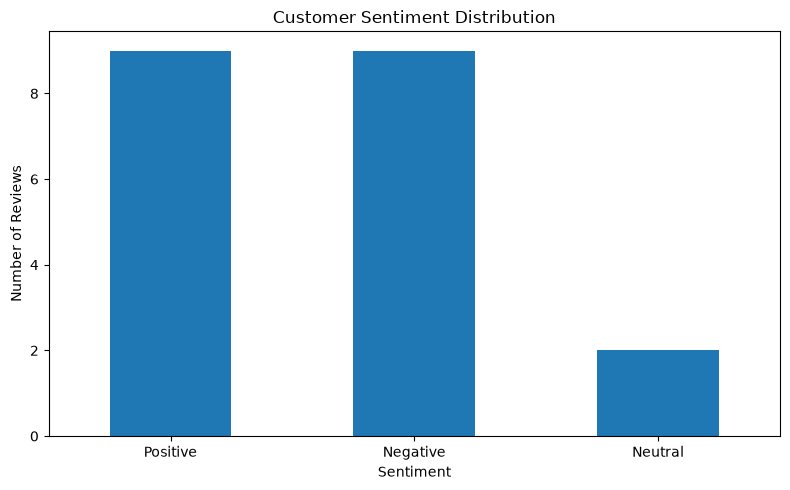

In [ ]:
import matplotlib.pyplot as plt

sentiment_count.plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Sentiment Distribution"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

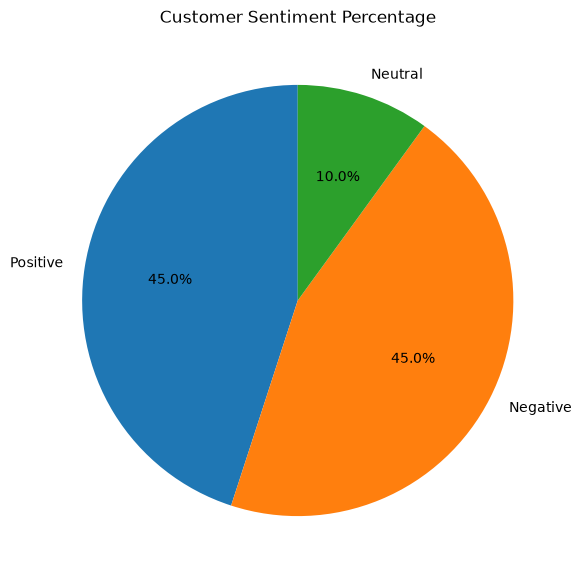

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_count,
    labels=sentiment_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Sentiment Percentage")
plt.show()

In [ ]:
# Calculate sentiment scores
df_reviews["Positive_Score"] = df_reviews["Review"].apply(
    lambda x: analyzer.polarity_scores(x)["pos"]
)

df_reviews["Negative_Score"] = df_reviews["Review"].apply(
    lambda x: analyzer.polarity_scores(x)["neg"]
)

df_reviews["Neutral_Score"] = df_reviews["Review"].apply(
    lambda x: analyzer.polarity_scores(x)["neu"]
)

display(df_reviews[[
    "Review",
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score"
]])

,Review,Positive_Score,Negative_Score,Neutral_Score
0,"Excellent product, I really love it!",0.680,0.000,0.320
1,Very poor quality and bad experience.,0.000,0.633,0.367
2,"The product is okay, nothing special.",0.233,0.277,0.490
3,Amazing quality and fast delivery.,0.487,0.000,0.513
4,I am disappointed with this product.,0.000,0.383,0.617
5,Average product for the price.,0.000,0.000,1.000
6,Excellent service and great packaging.,0.722,0.000,0.278
7,"Worst product, completely useless.",0.000,0.782,0.218
8,The product works as expected.,0.000,0.000,1.000
9,Very happy with my purchase.,0.500,0.000,0.500


In [ ]:
sentiment_analysis = (
    df_reviews.groupby("Sentiment")
    .agg(
        Total_Reviews=("ReviewID", "count"),
        Average_Positive_Score=("Positive_Score", "mean"),
        Average_Negative_Score=("Negative_Score", "mean"),
        Average_Neutral_Score=("Neutral_Score", "mean")
    )
)

print("Sentiment-wise Review Analysis:")
display(sentiment_analysis.round(2))

Sentiment-wise Review Analysis:


,Total_Reviews,Average_Positive_Score,Average_Negative_Score,Average_Neutral_Score
Sentiment,,,,
Negative,9,0.03,0.47,0.50
Neutral,2,0.00,0.00,1.00
Positive,9,0.52,0.00,0.48


In [ ]:
print("===== BUSINESS INSIGHTS =====")

print("Total Reviews:", len(df_reviews))

print("Positive Reviews:",
      (df_reviews["Sentiment"] == "Positive").sum())

print("Negative Reviews:",
      (df_reviews["Sentiment"] == "Negative").sum())

print("Neutral Reviews:",
      (df_reviews["Sentiment"] == "Neutral").sum())

print("\nMost Common Sentiment:",
      df_reviews["Sentiment"].value_counts().idxmax())

===== BUSINESS INSIGHTS =====
Total Reviews: 20
Positive Reviews: 9
Negative Reviews: 9
Neutral Reviews: 2

Most Common Sentiment: Positive


In [ ]:
recommendations = [
    "Improve product quality based on negative customer feedback.",
    "Maintain product features appreciated by positive reviewers.",
    "Analyze neutral reviews to identify improvement opportunities.",
    "Improve customer service and delivery experience.",
    "Use customer feedback to support product development."
]

print("===== BUSINESS RECOMMENDATIONS =====")

for i, item in enumerate(recommendations, start=1):
    print(f"{i}. {item}")

===== BUSINESS RECOMMENDATIONS =====
1. Improve product quality based on negative customer feedback.
2. Maintain product features appreciated by positive reviewers.
3. Analyze neutral reviews to identify improvement opportunities.
4. Improve customer service and delivery experience.
5. Use customer feedback to support product development.


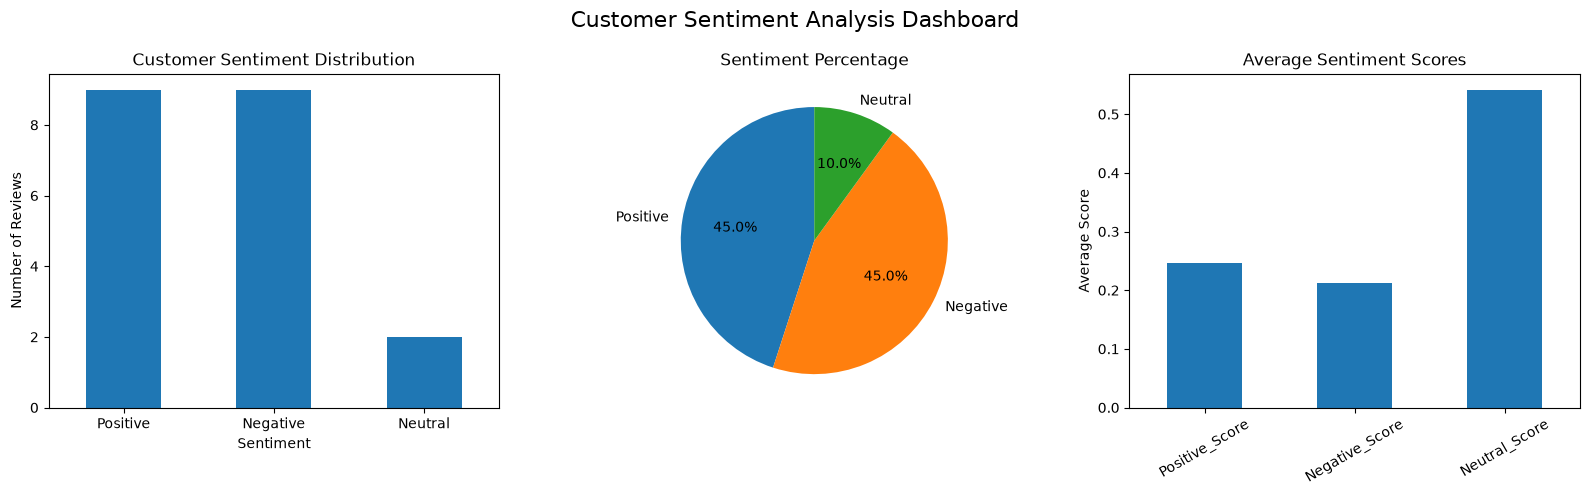

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Sentiment Bar Chart
sentiment_count.plot(kind="bar", ax=axes[0])
axes[0].set_title("Customer Sentiment Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Reviews")
axes[0].tick_params(axis="x", rotation=0)

# 2. Sentiment Pie Chart
axes[1].pie(
    sentiment_count,
    labels=sentiment_count.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Sentiment Percentage")

# 3. Sentiment Score Chart
score_data = df_reviews[
    ["Positive_Score", "Negative_Score", "Neutral_Score"]
].mean()

score_data.plot(kind="bar", ax=axes[2])
axes[2].set_title("Average Sentiment Scores")
axes[2].set_ylabel("Average Score")
axes[2].tick_params(axis="x", rotation=30)

plt.suptitle("Customer Sentiment Analysis Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
df_reviews.to_csv("Final_Sentiment_Analysis_Results.csv", index=False)

print("Final Sentiment Analysis Results Saved Successfully!")

Final Sentiment Analysis Results Saved Successfully!


# CodeAlpha Internship – Task 4
# Sentiment Analysis

## 1. Project Objective

The objective of this project is to analyze customer reviews using Natural Language Processing (NLP) techniques and classify customer opinions into Positive, Negative, and Neutral sentiments.

## 2. Dataset Overview

- Dataset: E-Commerce Customer Reviews
- Total Reviews: 20
- Columns: ReviewID, Review, Source
- Data Type: Text Data
- Dataset Source: Sample dataset created for this project

## 3. Text Preprocessing

The following text preprocessing operations were performed:

- Converted text into lowercase.
- Removed special characters.
- Removed unnecessary spaces.
- Created a cleaned review column.

## 4. Sentiment Analysis

VADER Sentiment Analyzer was used to analyze customer reviews.

Reviews were classified into three categories:

- Positive
- Negative
- Neutral

## 5. Sentiment Score Calculation

Sentiment scores were calculated using VADER.

The following scores were analyzed:

- Positive Score
- Negative Score
- Neutral Score

These scores help understand the sentiment composition of individual customer reviews.

## 6. Data Visualization

The following visualizations were created using Matplotlib:

- Sentiment Distribution Bar Chart
- Sentiment Percentage Pie Chart
- Average Sentiment Score Chart
- Final Sentiment Analysis Dashboard

These visualizations help understand customer opinions and sentiment distribution.

## 7. Business Insights

Customer reviews were analyzed to identify positive, negative, and neutral feedback patterns.

The sentiment distribution helps understand overall customer opinions about products and services.

## 8. Business Recommendations

1. Improve product quality based on negative customer feedback.
2. Maintain product features appreciated by customers.
3. Analyze neutral reviews to identify improvement opportunities.
4. Improve customer service and delivery experience.
5. Use customer feedback to support product development.

## 9. Conclusion

This project demonstrates how Python and Natural Language Processing techniques can be used to analyze customer reviews.

Sentiment classification and data visualization help businesses understand customer feedback and make better decisions.

## 10. Tools and Technologies

- Python
- Pandas
- VADER Sentiment Analyzer
- Matplotlib
- Jupyter Notebook